<style>
body, .reveal, .reveal .slides, .reveal .slides section,
.jp-RenderedHTMLCommon, .jp-MarkdownOutput, .rendered_html {
  font-family: Arial, "DejaVu Sans", "Noto Sans", "Liberation Sans", sans-serif !important;
  font-kerning: normal;
}
.reveal h1, .reveal h2, .reveal h3, .reveal h4,
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2,
.jp-RenderedHTMLCommon h3, .jp-RenderedHTMLCommon h4 {
  font-family: Arial, "DejaVu Sans", "Noto Sans", "Liberation Sans", sans-serif !important;
  font-weight: 600;
}
.reveal code, .reveal pre, .jp-RenderedHTMLCommon code, .jp-RenderedHTMLCommon pre {
  font-family: Menlo, Consolas, "DejaVu Sans Mono", "Liberation Mono", monospace !important;
}
</style>

# Python (data science) - Machine Learning

_Mikołaj Leszczuk_

## Konspekt

* Czym jest uczenie maszynowe?
* Dlaczego warto korzystać z uczenia maszynowego?
* Rodzaje systemów uczenia maszynowego
* Jak rozróżnić?
* Drzewo decyzyjne
* Las losowy

## Czym jest uczenie maszynowe?

"Uczenie maszynowe to dziedzina nauki dająca komputerom możliwość uczenia się bez konieczności ich jawnego programowania..." Arthur Samuel, 1959.

A bardziej technicznie:

"Mówimy ze program komputerowy uczy się na podstawie doświadczenia $E$ w odniesieniu do jakiegoś zadania $T$ i pewnej miary wydajności $P$, jeśli jego wydajność (mierzona przez $P$) wobec zadania $T$ wzrasta z nabywaniem doświadczenia $E$...", Tom Mitchell, 1997.

## Dlaczego warto korzystać z uczenia maszynowego?

Na tym diagramie widać podejście tradycyjne: programista zapisuje reguły, program dostaje dane wejściowe i na tej podstawie zwraca odpowiedź.

To działa dobrze, gdy reguły są stabilne i dają się łatwo opisać, ale przy filtrze spamu szybko zaczyna się robić długa lista wyjątków.

<img src="https://raw.githubusercontent.com/miklesz/Courses/main/Machine%20Learning/ml1.png" style="max-width: 760px; width: 82%; display: block; margin: 14px auto 0;">

Zadanie: napisać filtr spamu, przy pomocy tradycyjnych technik programistycznych
1. Zastanowienie jak wygląda klasyczny spam - powtarzające się wyrażenia: okazja, darmowe, bonus, promocja, gratis, bez limitów. Występowanie: temat wiadomości
2. Napisanie algorytmu wykrywającego każdy z zaobserwowanych szablonów. Program oznaczałby wiadomość jako spam, jeśli wykryłby jeden z kilku określonych wzorców.
3. Testowanie programu, ciągłe powtarzanie kroków 1. i 2.

=> a co jeśli spamerzy zauważyliby blokowanie algorytmu wykrywającego niepożądane mejle?

Próby omijania filtrów: wkomponowywanie białych znaków, znaków specjalnych

=> należy non stop uwzględniać nowe zmiany poprzez dopisywanie nowych reguł...

Najlepsze rozwiązanie?

Stworzenie samouczącego się algorytmu, na podstawie przykładów i kombinacji z nim związanych.

W podejściu uczenia maszynowego punktem wyjścia są dane oraz poprawne odpowiedzi z przeszłości. Algorytm uczy się wzorca, czyli tworzy model.

Potem model stosujemy do nowych przypadków. Gdy problem się zmienia, zwykle nie dopisujemy ręcznie kolejnych reguł, tylko aktualizujemy dane i trenujemy model ponownie.

<img src="https://raw.githubusercontent.com/miklesz/Courses/main/Machine%20Learning/ml2.png" style="max-width: 760px; width: 82%; display: block; margin: 14px auto 0;">

Wykorzystanie technik uczenia maszynowego do analizowania olbrzymich ilości danych może pomóc w wykrywaniu nieoczywistych wzorców. Proces nazywa się wydobywaniem danych (data mining).

Uczenie maszynowe nadaje się do:
1. Problemów, które wymagają częstego dostrajania algorytmu lub korzystania z długich list reguł.
2. Złożonych problemów, trudnych do rozwiązania tradycyjnymi metodami.
3. Zmiennych środowisk wpływających na problematykę.
4. Pomagania człowiekowi w analizowaniu skomplikowanych zagadnień i olbrzymich ilości danych.

## Rodzaje systemów uczenia maszynowego

### Uczenie nadzorowane

=> dane są oznakowane, jest zbiór uczący oraz zbiór weryfikacyjny

**Metody oparte na podobieństwie i liczbach**

* metoda k-najbliższych sąsiadów - nowy przykład dostaje etykietę na podstawie najbardziej podobnych przykładów z danych treningowych.
* regresja liniowa - przewiduje wartość liczbową, np. cenę mieszkania albo temperaturę.

**Metody do klasyfikacji**

* regresja logistyczna - mimo nazwy najczęściej służy do klasyfikacji, np. tak/nie, spam/nie spam.
* maszyna wektorów nośnych - szuka granicy możliwie dobrze rozdzielającej klasy.

**Modele bardziej elastyczne**

* drzewa decyzyjne i losowe lasy - budują reguły typu „jeśli cecha spełnia warunek, idź do kolejnej gałęzi”.
* sieci neuronowe - uczą się złożonych zależności przez wiele warstw prostych przekształceń.

### Uczenie nienadzorowane

=> dane uczące są nieoznakowane; program uczy się bez nauczyciela

**Grupowanie danych**

* metoda k-średnich lub centroidów (ang. _k-means_) - dzieli dane na grupy wokół wybranych środków skupień.
* hierarchiczna analiza skupień (ang. _Hierarchical Cluster Analysis_, HCA) - buduje drzewo podobieństwa między obserwacjami.

**Nietypowe przypadki i wizualizacja**

* wykrywanie anomalii i nowości (ang. _anomaly detection and novelty detection_) - wskazuje obserwacje nietypowe względem większości danych.
* wizualizacja i redukcja wymiarowości - upraszcza wiele cech do 2-3 wymiarów, żeby łatwiej zobaczyć strukturę danych.

## Jak rozróżnić?

**Analiza skupień**

Po lewej: dane bez etykiet. Po prawej: algorytm znajduje grupy podobnych obserwacji.

<img src="assets/ml-alternatives/clustering-before-after-balanced.png" style="max-width: 980px; width: 96%; display: block; margin: 14px auto 0;">

(autorska wizualizacja poglądowa)

Inny przykład to wykrywanie anomalii.

Po lewej nietypowe punkty nie są jeszcze mocno podkreślone, bo patrzymy tylko na surowy rozrzut danych. Po prawej model zaznacza typowy obszar obserwacji i oddziela punkty odstające, które mogą oznaczać błąd pomiaru, nietypowe zachowanie użytkownika albo przypadek wymagający ręcznej analizy.

<img src="assets/ml-alternatives/anomaly-before-after-balanced.png" style="max-width: 980px; width: 96%; display: block; margin: 14px auto 0;">

(autorska wizualizacja poglądowa)

Oczywiście jest wiele innych rodzajów "uczenia" maszynowego:

* Uczenie przez wzmacnianie (ang. _reinforcement learning_):

System uczący (zwany agentem) obserwuje środowisko i na tej podstawie wykonuje pewne czynności, a także odbiera nagrody lub kary.

Przykład: program uczący się grać w grę nie dostaje listy poprawnych ruchów, tylko informację, czy jego decyzje prowadzą do lepszego wyniku.

Agent obserwuje środowisko i wybiera działanie.

<img src="https://raw.githubusercontent.com/miklesz/Courses/main/Machine%20Learning/ml5_0.png" style="max-width: 680px; width: 74%; display: block; margin: 14px auto 0;">

Po działaniu środowisko się zmienia i agent dostaje informację zwrotną.

<img src="https://raw.githubusercontent.com/miklesz/Courses/main/Machine%20Learning/ml5_1.png" style="max-width: 680px; width: 74%; display: block; margin: 14px auto 0;">

Celem jest taka strategia działania, która w dłuższym czasie daje jak najlepszą sumę nagród.

<img src="https://raw.githubusercontent.com/miklesz/Courses/main/Machine%20Learning/ml5_2.png" style="max-width: 680px; width: 74%; display: block; margin: 14px auto 0;">

* Uczenie wsadowe:

Do nauki rozpoznawania (klasyfikacji) wykorzystywane są wszystkie dostępne dane. System nie jest w stanie trenować przyrostowo, więc jego nauka może wymagać dużo czasu i zasobów.

Przykład: model trenujemy raz na przygotowanym zbiorze, a po zebraniu nowych danych uruchamiamy trening od nowa.

* Uczenie przyrostowe:

System jest trenowany na bieżąco przez sekwencyjnie dostarczane dane, które mogą być pojedyncze lub przyjmować postać minipakietów (niewielkich zbiorów).

Przykład: model rekomendacji może aktualizować się po nowych kliknięciach użytkowników.

## Drzewo decyzyjne

### Wstęp teoretyczny 

**Drzewo decyzyjne** – graficzna metoda wspomagania **procesu decyzyjnego**, stosowana w **teorii decyzji**. **Algorytm** drzew decyzyjnych jest również stosowany w **uczeniu maszynowym** do pozyskiwania wiedzy na podstawie przykładów.

W **teorii decyzji** drzewo decyzyjne jest **drzewem decyzji** i ich możliwych konsekwencji (**stanów natury**). Zadaniem drzew decyzyjnych może być zarówno stworzenie planu, jak i rozwiązanie problemu decyzyjnego.

Metoda drzew decyzyjnych jest szczególnie przydatna w problemach decyzyjnych z licznymi, rozgałęziającymi się wariantami oraz w przypadku podejmowania decyzji w warunkach **ryzyka**.

#### Konstruowanie drzewa decyzyjnego

Rozpocznijmy od przykładu, który rozwiążemy przy pomocy drzewa decyzyjnego.

##### Decision Problem Example

_Student Leszek obudził się 25 minut przed egzaminem. Profesor był formalistą i nawet minuta spóźnienia wykluczała możliwość pisania egzaminu, Leszkowi groziła więc sesja poprawkowa. Sprawa była jednak znacznie bardziej skomplikowana, gdyż Leszek miał zamiar wyjechać do pracy do Stanów Zjednoczonych, zaś wcześniejszy powrót we wrześniu oznaczałby dla niego utratę 4000 zł zarobków. Jeżeli jednak zdążyłby dotrzeć na czas, to rodzice w nagrodę za dobre oceny kupiliby mu prezent (zazwyczaj wartości 500 zł)._

_Leszek musiał więc starannie przemyśleć, w jaki sposób dotrzeć do szkoły. Autobus nie wchodził w grę, jazda nim zajmowała co najmniej 40 minut. Pozostawała jeszcze inna możliwość – pożyczyć samochód ojca. Samochód ten jednak był w kiepskim stanie i szanse na dojechanie do szkoły wynosiły 90%, zaś w przypadku awarii Leszek musiałby pokryć część kosztów naprawy, gdyż ojciec od dawna winił go za zły stan samochodu (3 tys. zł). Oprócz tego musiał zdecydować, czy opłaca się jechać przez miasto szybko, czy wolno. Przy wolnej jeździe dotarłby na czas z prawdopodobieństwem 60%, natomiast przy szybkiej zdążyłby na pewno (Leszek potrafił naprawdę szybko jeździć). Mógł jednak zostać zatrzymany przez patrol policji, co groziło mandatem w wysokości 500 zł (prawdopodobieństwa trafienia na patrol – 20%)._

_Druga możliwość to wynajęcie taksówki, za którą trzeba będzie zapłacić 30 zł. Jednak taksówkę trzeba będzie znaleźć w ciągu kilku minut, co można wykonać z prawdopodobieństwem sukcesu 80% (jeżeli nie będzie taksówki w pobliżu, Leszek już nie zdąży). Aby ponaglić kierowcę, Leszek może wręczyć napiwek w wysokości 20 zł, co zwiększy szanse na dotarcie na czas do 85% (w przeciwnym wypadku tylko 70%)._

Jaką decyzję powinien podjąć Leszek?

##### Budowanie drzewa

Drzewo składa się z węzłów (decyzji i stanów natury) i gałęzi (możliwych wariantów). Tradycyjnie decyzje oznaczamy prostokątami, natomiast stany natury kołami.

Konstrukcję drzewa rozpoczynamy od korzenia. Na początku Leszek ma do wyboru: samochód lub taksówkę.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/9/94/Drzewo_decyzyjne_-_etap_1.svg/960px-Drzewo_decyzyjne_-_etap_1.svg.png" style="max-width: 520px; width: 58%; display: block; margin: 12px auto 0;">

Rozpatrzmy węzeł samochód. Mamy do czynienia z dwoma stanami natury: samochód zepsuje się albo dojedzie.

Sytuacja, w której samochód się zepsuje, jest już węzłem końcowym, bo Leszek nie ma wtedy kolejnego wyboru.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/0/02/Drzewo_decyzyjne_-_etap_2.svg/960px-Drzewo_decyzyjne_-_etap_2.svg.png" style="max-width: 560px; width: 62%; display: block; margin: 12px auto 0;">

W ten sposób kontynuujemy konstrukcję całego drzewa.

W prawidłowo skonstruowanym drzewie węzły decyzyjne i stanów natury powinny występować na przemian, zaś każda ścieżka powinna być zakończona węzłem końcowym.

#### Rozwiązywanie problemu decyzyjnego

Rozwiązywanie problemu przy pomocy drzewa decyzyjnego rozpoczynamy od węzłów końcowych tego drzewa, przypisując im końcowe wypłaty. Przykładowo, dla sekwencji: taksówka → znajdzie → napiwek → zdąży, końcowa wypłata wynosi 4000 zł (zarobek w Stanach) + 500 zł (prezent) − 30 zł (koszt taksówki) − 20 zł (napiwek) = 4450 zł.

Następnym krokiem jest zaznaczenie przy gałęziach wychodzących ze stanów natury odpowiadających im prawdopodobieństw.

Przykład z szybką jazdą samochodem: gałąź „policja” ma prawdopodobieństwo 0,2, a gałąź „uda się” ma prawdopodobieństwo 0,8.

Kolejny krok to wyznaczenie dla każdego stanu natury wartości oczekiwanej.

Dla przykładu z szybką jazdą samochodem wartość oczekiwana wyniesie: 0,2 · (−500) zł + 0,8 · 4500 zł = 3500 zł.

Przy każdym węźle decyzyjnym zapisujemy największą wartość z wyznaczonych wartości oczekiwanych. Teraz podczas cofania się po drzewie do korzenia wypełniamy kolejno wszystkie węzły.

Optymalna ścieżka decyzji jest wyznaczona przez największe wartości oczekiwane.

W podanym przykładzie z obliczeń wynika, że Leszek powinien poszukać taksówki i dać taksówkarzowi napiwek.

### Budowanie modelu klasyfikacji dla zbioru danych "**_Iris_**"

(na podstawie: Chanin Nantasenamat, <i>Data Professor YouTube channel, http://youtube.com/dataprofessor</i>)

Będziemy budować model klasyfikacji dla zbioru danych "**_Iris_**" (kosaciec, irys) przy użyciu algorytmu drzewa decyzyjnego.

<img src="https://upload.wikimedia.org/wikipedia/commons/4/4c/Iris_sibirica_060603.jpg" style="max-width: 480px; width: 54%; display: block; margin: 12px auto 0;">

#### Importowanie bibliotek

Ten fragment wymaga pakietów `scikit-learn`, `numpy`, `pandas` i `matplotlib` w tym samym kernelu Jupyter, w którym uruchamiamy notebook.

Jeśli pojawi się `ModuleNotFoundError`, najpierw uruchom w osobnej komórce:

```python
%pip install scikit-learn numpy pandas matplotlib
```

In [2]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import make_classification

#### Load dataset **_Iris_**

`load_iris()` ładuje gotowy, klasyczny zbiór danych do nauki klasyfikacji. Dzięki temu nie musimy jeszcze czytać plików CSV ani przygotowywać danych ręcznie.

In [3]:
iris = datasets.load_iris()

#### Funkcje wejściowe


Zestaw danych "**_Iris_**" zawiera 4 cechy wejściowe i 1 zmienną wyjściową (etykieta klasy).

##### Funkcje wejściowe

`feature_names` to nazwy cech wejściowych, czyli kolumn, które model będzie widział jako dane `X`.

In [4]:
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Polskie odpowiedniki nazw cech:

* długość kielicha (cm)
* szerokość kielicha (cm)
* długość płatka (cm)
* szerokość płatka (cm)

##### Funkcje wyjściowe

`target_names` to nazwy klas, które model ma przewidywać. W samych danych klasy są zapisane jako liczby, ale tutaj widzimy ich znaczenie.

In [5]:
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


###### _Iris setosa_

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/a/a7/Irissetosa1.jpg/960px-Irissetosa1.jpg" style="max-width: 440px; width: 52%; display: block; margin: 12px auto 0;">

###### _Iris versicolor_

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/2/27/Blue_Flag%2C_Ottawa.jpg/960px-Blue_Flag%2C_Ottawa.jpg" style="max-width: 440px; width: 52%; display: block; margin: 12px auto 0;">

###### _Iris virginica_

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/f/f8/Iris_virginica_2.jpg/960px-Iris_virginica_2.jpg" style="max-width: 440px; width: 52%; display: block; margin: 12px auto 0;">

#### Spojrzenie na dane

##### Funkcje wejściowe

`iris.data` to macierz cech: każdy wiersz jest jednym kwiatem, a każda kolumna jedną mierzoną cechą.

In [6]:
print(iris.data)

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]
 [5.4 3.7 1.5 0.2]
 [4.8 3.4 1.6 0.2]
 [4.8 3.  1.4 0.1]
 [4.3 3.  1.1 0.1]
 [5.8 4.  1.2 0.2]
 [5.7 4.4 1.5 0.4]
 [5.4 3.9 1.3 0.4]
 [5.1 3.5 1.4 0.3]
 [5.7 3.8 1.7 0.3]
 [5.1 3.8 1.5 0.3]
 [5.4 3.4 1.7 0.2]
 [5.1 3.7 1.5 0.4]
 [4.6 3.6 1.  0.2]
 [5.1 3.3 1.7 0.5]
 [4.8 3.4 1.9 0.2]
 [5.  3.  1.6 0.2]
 [5.  3.4 1.6 0.4]
 [5.2 3.5 1.5 0.2]
 [5.2 3.4 1.4 0.2]
 [4.7 3.2 1.6 0.2]
 [4.8 3.1 1.6 0.2]
 [5.4 3.4 1.5 0.4]
 [5.2 4.1 1.5 0.1]
 [5.5 4.2 1.4 0.2]
 [4.9 3.1 1.5 0.2]
 [5.  3.2 1.2 0.2]
 [5.5 3.5 1.3 0.2]
 [4.9 3.6 1.4 0.1]
 [4.4 3.  1.3 0.2]
 [5.1 3.4 1.5 0.2]
 [5.  3.5 1.3 0.3]
 [4.5 2.3 1.3 0.3]
 [4.4 3.2 1.3 0.2]
 [5.  3.5 1.6 0.6]
 [5.1 3.8 1.9 0.4]
 [4.8 3.  1.4 0.3]
 [5.1 3.8 1.6 0.2]
 [4.6 3.2 1.4 0.2]
 [5.3 3.7 1.5 0.2]
 [5.  3.3 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.4 3.2 4.5 1.5]
 [6.9 3.1 4.

##### Zmienna wyjściowa (etykieta klasy)

`iris.target` to wektor etykiet klas. Dla każdego wiersza z `iris.data` mamy jedną odpowiedź: do którego gatunku należy kwiat.

In [7]:
print(iris.target)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


##### Wykresy kropkowe (scatter plots)

Przykład użycia tych parametrów na zbiorze Iris, zawierającym obserwacje trzech rodzajów kwiatów. W ten  sposób możemy pokazać wielowymiarowość danych - każda kropka oznacza jedną obserwacje, jej położenie mówi o rozmiarze kielichów, rozmiar kropki mówi o rozmiarze (szerokości) płatka kwiatu, a kolor przedstawia jego rodzaj.

In [8]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

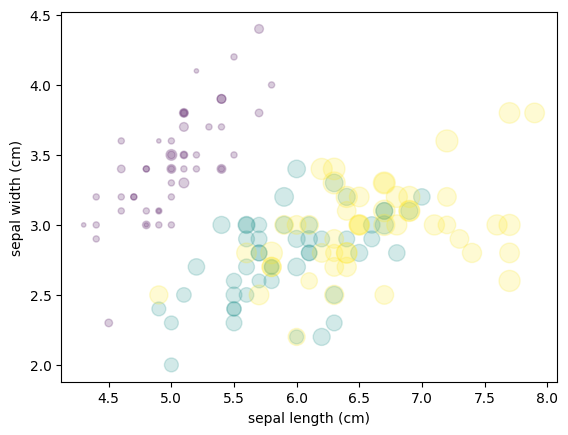

In [9]:
from sklearn.datasets import load_iris
iris = load_iris()
feat = iris.data.T  # features
plt.scatter(feat[0], feat[1], alpha=0.2, s=100*feat[3], c=iris.target, cmap='viridis')
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1]);

##### Przypisywanie zmiennych *wejściowych* i *wyjściowych*

Przypiszmy 4 zmienne wejściowe do `X`, a zmienną wyjściową (etykieta klasy) do `Y`.

In [10]:
X = iris.data
Y = iris.target

##### Przyjrzyjmy się wymiarowi danych

In [11]:
print(X.shape)

(150, 4)


In [12]:
print(Y.shape)

(150,)


#### Zbudujmy model klasyfikacji za pomocą drzewa decyzyjnego

Tworzymy obiekt klasyfikatora. `random_state=42` sprawia, że elementy losowe algorytmu są powtarzalne podczas zajęć.

In [13]:
clf = DecisionTreeClassifier(random_state=42)

Metoda `fit()` uczy model na danych. Przekazujemy cechy `X` i poprawne odpowiedzi `Y`, a model dopasowuje swoje reguły decyzyjne.

In [14]:
clf.fit(X, Y);

#### Znaczenie funkcji

`feature_importances_` pokazuje, które cechy były dla drzewa najbardziej użyteczne przy podejmowaniu decyzji. Suma wartości wynosi 1.

In [15]:
print(clf.feature_importances_)

[0.01333333 0.         0.56405596 0.42261071]


#### Dokonujemy prognozy

`predict()` zwraca przewidywaną klasę. `predict_proba()` zwraca prawdopodobieństwa klas. Skrót `proba` pochodzi od angielskiego _probability_, więc nie chodzi o „próbę” w sensie próbki danych.

In [16]:
X[0]

array([5.1, 3.5, 1.4, 0.2])

In [17]:
print(clf.predict([[5.1, 3.5, 1.4, 0.2]]))

[0]


In [18]:
print(clf.predict(X[[0]]))

[0]


In [19]:
print(clf.predict_proba(X[[0]]))

[[1. 0. 0.]]


In [20]:
clf.fit(iris.data, iris.target_names[iris.target]);

#### Train/test split (80/20)

Ustawiamy `random_state`, żeby wyniki były powtarzalne, oraz `stratify=Y`, żeby zachować proporcje klas.

In [21]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [22]:
X_train.shape, Y_train.shape

((120, 4), (120,))

In [23]:
X_test.shape, Y_test.shape

((30, 4), (30,))

#### Przebudujmy model drzewa decyzyjnego

Po podziale danych uczymy model ponownie tylko na zbiorze treningowym. Zbiór testowy zostawiamy do sprawdzenia, jak model radzi sobie z danymi, których nie widział podczas treningu.

In [24]:
clf.fit(X_train, Y_train);

##### Wykonajmy prognozę na pojedynczej próbce ze zbioru danych

In [25]:
print(clf.predict([[5.1, 3.5, 1.4, 0.2]]))

[0]


In [26]:
print(clf.predict_proba([[5.1, 3.5, 1.4, 0.2]]))

[[1. 0. 0.]]


##### Wykonajmy prognozę na zbiorze testowym

###### *Przewidywane etykiety klas*

In [27]:
print(clf.predict(X_test))

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


###### *Rzeczywiste etykiety klas*

In [28]:
print(Y_test)

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


#### Wydajność modelu

Dla klasyfikatorów `score()` zwraca dokładność (`accuracy`): odsetek przykładów testowych, które model sklasyfikował poprawnie.

In [29]:
print(clf.score(X_test, Y_test))

0.9333333333333333


## Las losowy

### Wstęp teoretyczny 

**Las losowy** (ang. _random forest_, losowy las decyzyjny) to **metoda zespołowa**.

Zamiast uczyć jedno drzewo decyzyjne, uczymy wiele drzew. Każde drzewo widzi trochę inną próbkę danych i/lub cech, więc każde może podjąć trochę inną decyzję.

W **klasyfikacji** drzewa głosują, a wynikiem jest najczęstsza klasa, czyli **dominanta**. W **regresji** zwykle bierzemy średnią przewidywań.

**Różnica względem pojedynczego drzewa:** jedno drzewo jest czytelne, ale łatwo może zapamiętać szczegóły danych treningowych.

Las losowy jest mniej czytelny, bo składa się z wielu drzew, ale zwykle jest stabilniejszy i ogranicza **nadmierne dopasowanie** (_overfitting_).

Na schemacie każde drzewo głosuje osobno, a las łączy ich decyzje w jeden wynik.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/7/76/Random_Forest_Diagram_Extra_Wide.png/960px-Random_Forest_Diagram_Extra_Wide.png" style="max-width: 1120px; width: 96%; display: block; margin: 10px auto 0;">

### Budowanie modelu klasyfikacji dla zbioru danych "**_Iris_**"

(na podstawie: Chanin Nantasenamat, <i>Data Professor YouTube channel, http://youtube.com/dataprofessor</i>)

Będziemy budować model klasyfikacji dla zbioru danych "**_Iris_**" przy użyciu algorytmu losowego lasu.

#### Importowanie bibliotek

In [30]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

#### Load dataset **_Iris_**

In [31]:
iris = datasets.load_iris()

##### Przypisywanie zmiennych *wejściowych* i *wyjściowych*

Przypiszmy 4 zmienne wejściowe do `X`, a zmienną wyjściową (etykieta klasy) do `Y`.

In [32]:
X = iris.data
Y = iris.target

#### Zbudujmy model klasyfikacji za pomocą losowego lasu

Las losowy powtarza ten sam pomysł wiele razy: tworzy wiele drzew decyzyjnych, a końcowa predykcja jest wynikiem głosowania drzew.

In [ ]:
clf = RandomForestClassifier(random_state=42)

Trening lasu trwa zwykle dłużej niż trening pojedynczego drzewa, ale model bywa stabilniejszy i mniej podatny na nadmierne dopasowanie.

In [33]:
clf.fit(X, Y);

#### Znaczenie funkcji

W lesie losowym znaczenie cech jest uśredniane po wielu drzewach, dlatego wynik bywa mniej przypadkowy niż dla pojedynczego drzewa.

In [34]:
print(clf.feature_importances_)

[0.01333333 0.         0.56405596 0.42261071]


#### Dokonujemy prognozy

In [35]:
X[0]

array([5.1, 3.5, 1.4, 0.2])

In [36]:
print(clf.predict([[5.1, 3.5, 1.4, 0.2]]))

[0]


In [37]:
print(clf.predict(X[[0]]))

[0]


In [38]:
print(clf.predict_proba(X[[0]]))

[[1. 0. 0.]]


In [39]:
clf.fit(iris.data, iris.target_names[iris.target]);

#### Train/test split (80/20)

Ustawiamy `random_state`, żeby wyniki były powtarzalne, oraz `stratify=Y`, żeby zachować proporcje klas.

In [40]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [41]:
X_train.shape, Y_train.shape

((120, 4), (120,))

In [42]:
X_test.shape, Y_test.shape

((30, 4), (30,))

#### Przebudujmy model losowego lasu

In [43]:
clf.fit(X_train, Y_train);

##### Wykonajmy prognozę na pojedynczej próbce ze zbioru danych

In [44]:
print(clf.predict([[5.1, 3.5, 1.4, 0.2]]))

[0]


In [45]:
print(clf.predict_proba([[5.1, 3.5, 1.4, 0.2]]))

[[1. 0. 0.]]


##### Wykonajmy prognozę na zbiorze testowym

###### *Przewidywane etykiety klas*

In [46]:
print(clf.predict(X_test))

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


###### *Rzeczywiste etykiety klas*

In [47]:
print(Y_test)

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


#### Wydajność modelu

Ten wynik porównujemy z wynikiem pojedynczego drzewa. Na małym zbiorze Iris oba modele mogą być bardzo dobre, więc różnice nie zawsze będą duże.

In [48]:
print(clf.score(X_test, Y_test))

0.9333333333333333


## Podsumowanie

* Uczenie nadzorowane korzysta z danych z poprawnymi odpowiedziami; uczenie nienadzorowane szuka struktury bez etykiet.
* Drzewo decyzyjne jest czytelne, bo działa jak seria pytań i odpowiedzi, ale może nadmiernie dopasować się do danych.
* Las losowy łączy wiele drzew, dzięki czemu zwykle daje stabilniejsze przewidywania.
* Podział na dane treningowe i testowe pozwala sprawdzić, czy model działa także na nowych przykładach.
* `accuracy` jest dobrym pierwszym wynikiem, ale przy trudniejszych lub niezbalansowanych danych trzeba patrzeć także na inne metryki.